# AE 370 Project 1 — Method section studies

Numerical evidence for Section 2 of the report. Every time integrator below is written from scratch; `fsolve` is used only for the algebraic solve inside the implicit methods.

| Notebook part | Report section |
|---|---|
| 1. Jacobian & eigenvalues | 2.2 |
| 2. Truncation error & convergence | 2.3 |
| 3. Absolute stability & stiffness | 2.4, 2.5 |
| 4. Comparison of methods | 2.6 |
| 5. Algorithm: RK4 to burnout | 2.7 |

`feed_model_upgrade.py` must be in the same folder, or its contents pasted into the first code cell in place of the import. Run the cells top to bottom; the full notebook takes about 1–2 minutes.

In [1]:
import os, time, warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd                       # !pip install pandas if not installed
from scipy.optimize import fsolve
from feed_model_upgrade import *          # model: f, jacobian, info, ... (or paste the module here)

p  = make_params()                        # nominal case: P_set = P_u0 = 360 psig
u0 = initial_state(p)
T_END = 27.6                              # fixed horizon just before burnout (t_f ~ 27.9 s); = 69 x 0.4 s
TOL   = 1e-2                              # accuracy target: 1% on mdot_f
np.seterr(all="ignore"); warnings.filterwarnings("ignore")   # unstable runs overflow on purpose
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)     # report figures are saved here as PDF

## Numerical Method

Lecture 10–13 notation: `u` is the state and `y1..y4` are RK stages. `advance()` takes one step $u_k \to u_{k+1}$ for any method. `march()` repeats it, starts multi-step methods with RK4 (Lecture 11), and stops if the solution blows up.

In [2]:
class Counted:
    "Wraps a function and counts its calls (cost = evaluations of f and J)."
    def __init__(self, fun): self.fun, self.n = fun, 0
    def __call__(self, u):
        self.n += 1
        return self.fun(u)

AB   = {"AB2": [-1/2, 3/2], "AB4": [-9/24, 37/24, -59/24, 55/24]}   # beta, oldest first (Lecture 11)
HIST = {"AB2": 2, "AB4": 4, "BDF2": 2}                                # past values each multi-step method needs
SCALE = np.abs(u0)                                                    # states differ by 1e4 in size -> scale the solve

def rk4_step(rhs, u, dt):
    y1 = rhs(u); y2 = rhs(u + dt/2*y1); y3 = rhs(u + dt/2*y2); y4 = rhs(u + dt*y3)
    return u + dt/6*(y1 + 2*y2 + 2*y3 + y4)

def solve_implicit(G, dG, guess):
    "Solve G(z) = 0 with fsolve, using the analytic Jacobian dG, in scaled variables x = z / SCALE."
    s = SCALE
    x = fsolve(lambda x: G(x*s)/s, guess/s, fprime=lambda x: dG(x*s)*s[None, :]/s[:, None], xtol=1e-12)
    return x*s

def advance(method, Uh, Fh, dt, rhs, jac):
    "One step. Uh = [..., u_{k-1}, u_k]; Fh = [..., f(u_{k-1}), f(u_k)] (Adams-Bashforth only)."
    u, I = Uh[-1], np.eye(5)
    if method == "FE":
        return u + dt*rhs(u)
    if method == "Heun":
        y1 = rhs(u); y2 = rhs(u + dt*y1)
        return u + dt/2*(y1 + y2)
    if method == "RK4":
        return rk4_step(rhs, u, dt)
    if method in AB:                                    # u_{k+1} = u_k + dt * sum(beta_j f_j)
        b = AB[method]
        return u + dt*sum(bj*fj for bj, fj in zip(b, Fh[-len(b):]))
    if method == "BE":                                  # z - u_k - dt f(z) = 0
        return solve_implicit(lambda z: z - u - dt*rhs(z), lambda z: I - dt*jac(z), u + dt*rhs(u))
    if method == "Trap":                                # z - u_k - dt/2 (f(u_k) + f(z)) = 0
        fu = rhs(u)
        return solve_implicit(lambda z: z - u - dt/2*(fu + rhs(z)), lambda z: I - dt/2*jac(z), u + dt*fu)
    if method == "BDF2":                                # 3z - 4u_k + u_{k-1} - 2 dt f(z) = 0
        return solve_implicit(lambda z: 3*z - 4*u + Uh[-2] - 2*dt*rhs(z), lambda z: 3*I - 2*dt*jac(z), u + dt*rhs(u))
    raise ValueError(method)

def march(method, dt, n):
    "n steps of size dt from u0. Returns U (rows = u_k; nan after a blow-up) and call counts."
    rhs, jac = Counted(lambda u: f(u, p)), Counted(lambda u: jacobian(u, p))
    U = np.full((n + 1, 5), np.nan); U[0] = u0
    Fh = [rhs(u0)] if method in AB else []
    try:
        for k in range(n):
            m = method if k + 1 >= HIST.get(method, 1) else "RK4"     # RK4 starter
            un = advance(m, U[:k + 1], Fh, dt, rhs, jac)
            if not np.all(np.isfinite(un)) or np.any(un[:4] <= 0):    # blew up / unphysical
                break
            U[k + 1] = un
            if method in AB:
                Fh.append(rhs(un))
    except (ValueError, ArithmeticError):
        pass
    return U, {"f": rhs.n, "J": jac.n}

## Reference solution and error metric

The reference is RK4 with $\Delta t_{ref} = 0.4/2^{10}$ s. Every $\Delta t$ in the sweeps is $0.4/2^j$, so the grids line up exactly. The error metric is Eq. (target) of the report: the maximum relative error of $\dot m_f$ over the burn.

In [3]:
DT_REF = 0.4/2**10
N_REF  = int(round(T_END/DT_REF))
T_REF  = np.arange(N_REF + 1)*DT_REF
t0 = time.perf_counter()
U_REF, _ = march("RK4", DT_REF, N_REF)
MF_REF = np.array([mdot_f(u, p) for u in U_REF])
print(f"reference: {N_REF} RK4 steps in {time.perf_counter() - t0:.1f} s")

def err_mdotf(U, dt):
    "e_mdotf = max_k |mdot_f(u_k) - mdot_f(u(t_k))| / mdot_f(u(t_k));  nan if the run blew up."
    if np.isnan(U).any():
        return np.nan
    ref = MF_REF[::int(round(dt/DT_REF))][:len(U)]
    m = np.array([mdot_f(u, p) for u in U])
    return np.max(np.abs(m - ref)/ref)

# reference accuracy: RK4 at 2*dt_ref has ~2^4 = 16x the error of the reference itself
U2, _ = march("RK4", 2*DT_REF, N_REF//2)
print(f"estimated reference error in mdot_f: {err_mdotf(U2, 2*DT_REF)/15:.1e}")
print(f"regimes visited after t = 0: {set(info(u, p)['regime'] for u in U_REF[1:])}")

reference: 70656 RK4 steps in 6.5 s


estimated reference error in mdot_f: 2.9e-13


regimes visited after t = 0: {'droop'}


## 1. Jacobian & eigenvalues  (report Sec. 2.2)

First, check the analytic Jacobian, Eqs. (13)–(17), against central differences. Then compute the eigenvalues at states along the reference solution.

In [4]:
# --- analytic J vs central differences along the burn ---
chk = np.linspace(1, N_REF, 25).astype(int)
rel = [np.max(np.abs(jacobian(U_REF[i], p) - jacobian_fd(U_REF[i], p)))/np.max(np.abs(jacobian_fd(U_REF[i], p)))
       for i in chk]
print(f"analytic vs central-difference Jacobian: max relative difference = {max(rel):.1e}")

# --- eigenvalues every 0.0125 s, sorted ascending: lam1 (fastest decay) ... lam5 ---
IDX_E = np.r_[1, np.arange(32, N_REF + 1, 32)]
T_E   = T_REF[IDX_E]
EIG   = np.array([np.linalg.eigvals(jacobian(U_REF[i], p)) for i in IDX_E])
print(f"largest |imaginary part| of any eigenvalue: {np.abs(EIG.imag).max():.1e}  (all real)")
LAM   = np.sort(EIG.real, axis=1)
i_max = np.argmax(-LAM[:, 0])
LAM_MAX, T_LAM_MAX = -LAM[i_max, 0], T_E[i_max]
print(f"|lambda|_max = {LAM_MAX:.3f} 1/s at t* = {T_LAM_MAX:.3f} s")

# --- Table 1 of the report ---
T_STAR = [T_REF[1], T_LAM_MAX, 1, 5, 10, 20, T_END]
def lam_at(t):
    return np.sort(np.linalg.eigvals(jacobian(U_REF[int(round(t/DT_REF))], p)).real)
tab1 = pd.DataFrame([lam_at(t) for t in T_STAR], columns=[f"lam{j}" for j in range(1, 6)])
tab1.insert(0, "t* [s]", np.round(T_STAR, 3))
display(tab1.style.format({"t* [s]": "{:.3f}", **{f"lam{j}": "{:.3e}" for j in range(1, 6)}}))

analytic vs central-difference Jacobian: max relative difference = 3.0e-10
largest |imaginary part| of any eigenvalue: 0.0e+00  (all real)


|lambda|_max = 8.534 1/s at t* = 0.475 s


,t* [s],lam1,lam2,lam3,lam4,lam5
0,0.000,-6.523e+00,-9.849e-02,-6.696e-06,-1.104e-10,1.147e-10
1,0.475,-8.534e+00,-1.645e-01,-2.053e-03,-9.724e-15,9.181e-05
2,1.000,-7.755e+00,-1.478e-01,-2.093e-03,1.359e-14,9.655e-05
3,5.000,-4.116e+00,-8.020e-02,-2.132e-03,-1.547e-15,9.828e-05
4,10.000,-2.605e+00,-5.104e-02,-2.182e-03,3.497e-16,1.012e-04
5,20.000,-1.514e+00,-2.960e-02,-2.289e-03,-1.946e-16,1.081e-04
6,27.600,-1.156e+00,-2.248e-02,-2.376e-03,-1.433e-16,1.141e-04


,t* [s],1/|lam1| [s],1/|lam2| [s],1/|lam3| [s],lam3 / (-(g-1) mdot_p/m_p),lam5 [1/s],|c^T J|/|J|
0,0.48,0.12,6.1,487,1.022,9.18e-05,0e+00
1,1.00,0.13,6.8,478,1.023,9.66e-05,0e+00
2,5.00,0.24,12.5,469,1.018,9.83e-05,0e+00
3,10.00,0.38,19.6,458,1.012,1.01e-04,0e+00
4,20.00,0.66,33.8,437,0.999,1.08e-04,0e+00
5,27.60,0.86,44.5,421,0.987,1.14e-04,0e+00


max lam5 * T_end = 3.1e-03  (physical growth over the burn)


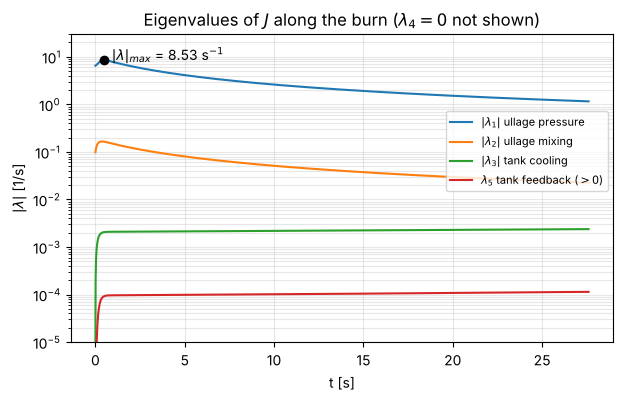

In [5]:
# --- what each mode is (report Sec. 2.2 bullets): time scales + the checks the text quotes ---
c = np.array([1, 0, 1, 0, 0])                                         # N2 mass m_p + m_u: c^T f = 0 -> c^T J = 0 (lam4 = 0)
rows = []
for t in T_STAR[1:]:
    u = U_REF[int(round(t/DT_REF))]; J = jacobian(u, p); lam = np.sort(np.linalg.eigvals(J).real)
    lam3_iso = -(p["G"] - 1)*info(u, p)["mdot_p"]/u[0]               # isentropic tank cooling, -(gamma-1) mdot_p/m_p
    rows.append([t, -1/lam[0], -1/lam[1], -1/lam[2], lam[2]/lam3_iso, lam[4],
                 np.abs(c @ J).max()/np.abs(J).max()])
modes = pd.DataFrame(rows, columns=["t* [s]", "1/|lam1| [s]", "1/|lam2| [s]", "1/|lam3| [s]",
                                    "lam3 / (-(g-1) mdot_p/m_p)", "lam5 [1/s]", "|c^T J|/|J|"])
display(modes.style.format({"t* [s]": "{:.2f}", "1/|lam1| [s]": "{:.2f}", "1/|lam2| [s]": "{:.1f}",
                            "1/|lam3| [s]": "{:.0f}", "lam3 / (-(g-1) mdot_p/m_p)": "{:.3f}",
                            "lam5 [1/s]": "{:.2e}", "|c^T J|/|J|": "{:.0e}"}))
print(f"max lam5 * T_end = {LAM[:, 4].max()*T_END:.1e}  (physical growth over the burn)")

fig, ax = plt.subplots(figsize=(7, 4))
for j, lab in [(0, r"$|\lambda_1|$ ullage pressure"), (1, r"$|\lambda_2|$ ullage mixing"),
               (2, r"$|\lambda_3|$ tank cooling"), (4, r"$\lambda_5$ tank feedback ($>0$)")]:
    ax.semilogy(T_E, np.abs(LAM[:, j]), label=lab)
ax.plot(T_LAM_MAX, LAM_MAX, "ko"); ax.annotate(rf"  $|\lambda|_{{max}}$ = {LAM_MAX:.2f} s$^{{-1}}$", (T_LAM_MAX, LAM_MAX))
ax.set(xlabel="t [s]", ylabel=r"$|\lambda|$ [1/s]", title=r"Eigenvalues of $J$ along the burn ($\lambda_4 = 0$ not shown)")
ax.set_ylim(1e-5, 30); ax.legend(fontsize=8, loc="center right", bbox_to_anchor=(1, 0.62)); ax.grid(True, which="both", alpha=0.3)
fig.savefig(f"{FIG_DIR}/fig_eigenvalues.pdf", bbox_inches="tight"); plt.show()

## 2. Truncation error & convergence  (report Sec. 2.3)

- **(a) Truncation error** $\tau_k$ (Lecture 11): one step from *exact* data (the reference), divided by $\Delta t$, at $t_k = 2$ s. It should fall as $\Delta t^p$, even where the method is unstable.
- **(b) Global error** $e_{\dot m_f}$ over the whole burn. It falls as $\Delta t^p$ only where the method is also stable; dashed vertical lines mark each explicit method's predicted wall, $\Delta t_{stab} = w^*/|\lambda|_{max}$.

In [6]:
#            order p, implicit?, w* (Lecture 12; None = whole negative real axis)
METHODS = {"FE": (1, False, 2.0), "Heun": (2, False, 2.0), "RK4": (4, False, 2.785),
           "AB2": (2, False, 1.0), "AB4": (4, False, 0.3),
           "BE": (1, True, None), "Trap": (2, True, None), "BDF2": (2, True, None)}
COL = dict(zip(METHODS, plt.cm.tab10.colors))
STY = lambda m: "--" if METHODS[m][1] else "-"

# --- (a) truncation error at t_k = 2 s ---
def tau(method, dt, tk=2.0):
    "tau_k = (u(t_k+1) - u~_k+1)/dt, u~ = one step from exact history. Max relative component [1/s]."
    s, k = int(round(dt/DT_REF)), int(round(tk/DT_REF))
    ex = lambda j: U_REF[k + j*s]                               # exact u(t_k + j dt)
    rhs, jac = (lambda u: f(u, p)), (lambda u: jacobian(u, p))
    n = HIST.get(method, 1)
    Uh = [ex(j) for j in range(1 - n, 1)]
    un = advance(method, Uh, [rhs(v) for v in Uh], dt, rhs, jac)
    return np.max(np.abs((ex(1) - un)/ex(0)))/dt

DTS_TAU = 0.4/2**np.arange(6)                                   # 0.4 ... 0.0125 s
TAU = {m: [tau(m, dt) for dt in DTS_TAU] for m in METHODS}

# --- (b) global error over the burn: the step-size sweep used for everything below ---
DTS = 0.4/2**np.arange(9)                                       # 0.4 ... 1.6e-3 s
RUNS = {}                                                       # (method, dt) -> err, f/J counts, wall time
t0 = time.perf_counter()
for m, (pm, impl, _) in METHODS.items():
    for dt in (DTS[:8] if impl else DTS):                        # implicit runs are slow; skip the finest dt
        tw = time.perf_counter()
        U, cnt = march(m, dt, int(round(T_END/dt)))
        RUNS[m, dt] = dict(err=err_mdotf(U, dt), time=time.perf_counter() - tw, **cnt)
print(f"sweep: {len(RUNS)} runs in {time.perf_counter() - t0:.0f} s")
dts_of = lambda m: np.array(sorted(dt for (mm, dt) in RUNS if mm == m))
err_of = lambda m: np.array([RUNS[m, dt]["err"] for dt in dts_of(m)])

# --- largest step meeting the 1% target, found with real runs (used in Secs. 3 and 4) ---
def run_s(m, s):
    "Run m at dt = s*dt_ref over N_REF//s steps (ends within one dt of T_END)."
    dt = s*DT_REF
    tw = time.perf_counter()
    U, cnt = march(m, dt, N_REF//s)
    return dict(dt=dt, err=err_mdotf(U, dt), time=time.perf_counter() - tw, **cnt)

def dt_1pct(m):
    "Bracket from the sweep (last passing, first failing dt), then bisect on the integer s."
    d, e = dts_of(m), err_of(m)
    i = 0
    while i + 1 < len(d) and e[i + 1] <= TOL:                    # nan (blow-up) compares False -> stops
        i += 1
    best = dict(dt=d[i], **RUNS[m, d[i]])
    if i + 1 == len(d):
        return best
    lo, hi = int(round(d[i]/DT_REF)), int(round(d[i + 1]/DT_REF))
    while hi - lo > 1:
        mid = (lo + hi)//2
        r = run_s(m, mid)
        lo, hi, best = (mid, hi, r) if r["err"] <= TOL else (lo, mid, best)
    return best

RUN_1 = {m: dt_1pct(m) for m in METHODS}
DT_1 = {m: RUN_1[m]["dt"] for m in METHODS}
print("dt meeting 1% [s]:", {m: round(v, 4) for m, v in DT_1.items()})

sweep: 69 runs in 40 s


dt meeting 1% [s]: {'FE': 0.0055, 'Heun': 0.0426, 'RK4': 0.1332, 'AB2': 0.0324, 'AB4': 0.0453, 'BE': 0.0059, 'Trap': 0.0723, 'BDF2': 0.0367}


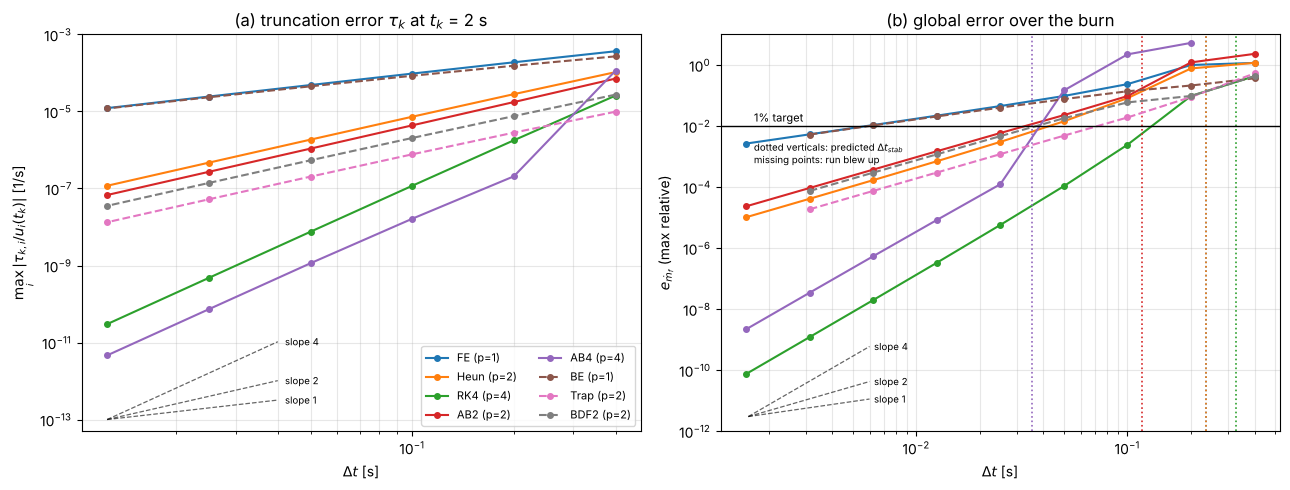

,FE,Heun,RK4,AB2,AB4,BE,Trap,BDF2
p (theory),1.00,2.00,4.00,2.00,4.00,1.00,2.00,2.00
slope of tau_k,1.00,1.99,3.99,2.00,3.97,0.96,1.97,1.97
slope of e_mdotf,1.01,2.02,4.02,2.00,3.98,0.98,2.00,1.99


In [7]:
from matplotlib.ticker import NullFormatter
def guides(ax, x0, x1, y0, orders=(1, 2, 4)):
    "Fan of slope guides from (x0, y0) to x1, labelled at the right end."
    for q in orders:
        x = np.array([x0, x1]); y = y0*(x/x0)**q
        ax.loglog(x, y, color="k", lw=0.9, ls="--", alpha=0.6)
        ax.text(x1*1.05, y[1], f"slope {q}", fontsize=7, va="center")

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for m, (pm, impl, ws) in METHODS.items():
    axs[0].loglog(DTS_TAU, TAU[m], STY(m), marker="o", ms=4, color=COL[m], label=f"{m} (p={pm})")
    axs[1].loglog(dts_of(m), err_of(m), STY(m), marker="o", ms=4, color=COL[m], label=f"{m} (p={pm})")
    if ws:                                                      # predicted stability wall (explicit only)
        axs[1].axvline(ws/LAM_MAX, color=COL[m], ls=":", lw=1.2)
guides(axs[0], 0.0125, 0.04, 1e-13)
guides(axs[1], 1.6e-3, 6e-3, 3e-12)
axs[0].set(title=r"(a) truncation error $\tau_k$ at $t_k$ = 2 s", ylabel=r"$\max_i |\tau_{k,i}/u_i(t_k)|$ [1/s]", ylim=(5e-14, 1e-3))
axs[1].set(title=r"(b) global error over the burn", ylabel=r"$e_{\dot m_f}$ (max relative)", ylim=(1e-12, 10))
axs[1].axhline(TOL, color="k", lw=1); axs[1].text(1.7e-3, TOL*1.4, "1% target", fontsize=8)
axs[1].text(1.7e-3, 3e-3, r"dotted verticals: predicted $\Delta t_{stab}$" "\nmissing points: run blew up", fontsize=7, va="top")
for ax in axs:
    ax.set_xlabel(r"$\Delta t$ [s]"); ax.grid(True, which="both", alpha=0.3)
    ax.xaxis.set_minor_formatter(NullFormatter())
axs[0].legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_convergence.pdf", bbox_inches="tight"); plt.show()

# observed order: least-squares slope over the 3 smallest dt with error above the reference floor (1e-11)
def observed_p(dts, errs):
    ok = np.isfinite(errs) & (errs > 1e-11)
    d, e = dts[ok][:3], errs[ok][:3]
    return np.polyfit(np.log(d), np.log(e), 1)[0]
OBS_P = {m: observed_p(dts_of(m), err_of(m)) for m in METHODS}

# accuracy-only step from the asymptotic fit e ~ C dt^p (ignores stability) -- for the stiffness test
def dt_acc_fit(m):
    pm = METHODS[m][0]; d, e = dts_of(m), err_of(m)
    ok = np.isfinite(e) & (e > 1e-11)
    C = np.median(e[ok][:3]/d[ok][:3]**pm)
    return (TOL/C)**(1/pm)
DT_ACC = {m: dt_acc_fit(m) for m in METHODS}
OBS_TAU = {m: np.polyfit(np.log(DTS_TAU[-3:]), np.log(TAU[m][-3:]), 1)[0] for m in METHODS}
display(pd.DataFrame({"p (theory)": {m: v[0] for m, v in METHODS.items()},
                      "slope of tau_k": OBS_TAU, "slope of e_mdotf": OBS_P}).T.style.format("{:.2f}"))

## 3. Absolute stability & stiffness  (report Sec. 2.4, 2.5)

The model problem $\dot u = \lambda u$ with $w = \Delta t\lambda$ (Lecture 12):
- one-step methods give $u_{k+1} = R(w)\,u_k$, stable where $|R(w)| < 1$;
- multi-step methods are stable where every root $\zeta$ of the characteristic polynomial has $|\zeta| < 1$.

All our eigenvalues are real, so the number that matters is $w^*$, where the region crosses the negative real axis.

In [8]:
R_ONE = {"FE":   lambda w: 1 + w,
         "Heun": lambda w: 1 + w + w**2/2,
         "RK4":  lambda w: 1 + w + w**2/2 + w**3/6 + w**4/24,
         "BE":   lambda w: 1/(1 - w),
         "Trap": lambda w: (1 + w/2)/(1 - w/2)}
CHAR  = {"AB2":  lambda w: [1, -(1 + 1.5*w), 0.5*w],                              # zeta^2 - zeta = w(3/2 zeta - 1/2)
         "AB4":  lambda w: [1, -1 - 55/24*w, 59/24*w, -37/24*w, 9/24*w],
         "BDF2": lambda w: [3 - 2*w, -4, 1]}                                     # 3zeta^2 - 4zeta + 1 = 2w zeta^2

def amp(m, w):
    "Growth factor per step: |R(w)| (one-step) or the largest |zeta| (multi-step)."
    return abs(R_ONE[m](w)) if m in R_ONE else np.max(np.abs(np.roots(CHAR[m](w))))

def w_star(m, wmax=50.0):
    "First w < 0 (moving left from 0) where the method stops being stable; None if stable to -wmax."
    ws = -np.linspace(1e-3, wmax, 5001)
    bad = [w for w in ws if amp(m, w) >= 1]
    if not bad:
        return None
    lo, hi = bad[0] + (ws[0] - ws[1]), bad[0]                     # bracket, then bisect
    for _ in range(50):
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if amp(m, mid) < 1 else (lo, mid)
    return -(lo + hi)/2

W_STAR = {m: w_star(m) for m in METHODS}
display(pd.DataFrame({"w* computed": {m: W_STAR[m] if W_STAR[m] else np.inf for m in METHODS},
                      "w* Lecture 12": {m: v[2] if v[2] else np.inf for m, v in METHODS.items()}}).T
        .style.format("{:.4f}"))

,FE,Heun,RK4,AB2,AB4,BE,Trap,BDF2
w* computed,2.0000,2.0000,2.7853,1.0000,0.3000,inf,inf,inf
w* Lecture 12,2.0000,2.0000,2.7850,1.0000,0.3000,inf,inf,inf


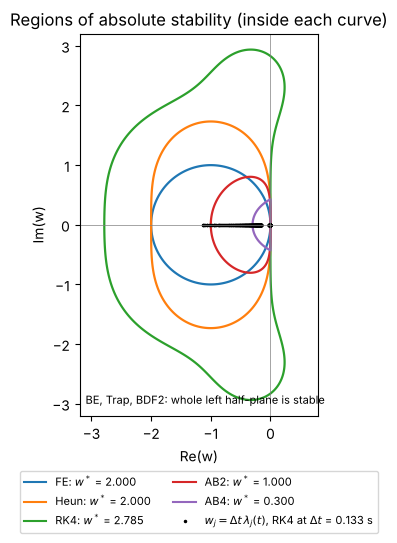

In [9]:
# regions of absolute stability + RK4's operating points w_j = dt * lambda_j(t) at its 1% step
EXPL = [m for m in METHODS if W_STAR[m]]
fig, ax = plt.subplots(figsize=(6.5, 5.6))
x, y = np.meshgrid(np.linspace(-3.2, 0.8, 241), np.linspace(-3.2, 3.2, 241))
W = x + 1j*y
for m in EXPL:
    A = np.vectorize(lambda w: amp(m, w))(W)
    ax.contour(x, y, A, levels=[1], colors=[COL[m]], linewidths=1.6)
    ax.plot([], [], color=COL[m], label=f"{m}: $w^*$ = {W_STAR[m]:.3f}")
w_rk4 = DT_1["RK4"]*LAM[:, :3].ravel()                                 # decaying modes, all t
ax.plot(w_rk4[::10], 0*w_rk4[::10], "k.", ms=3, label=rf"$w_j = \Delta t\,\lambda_j(t)$, RK4 at $\Delta t$ = {DT_1['RK4']:.3f} s")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set(xlabel="Re(w)", ylabel="Im(w)", title="Regions of absolute stability (inside each curve)", aspect="equal")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax.text(-3.1, -3.0, "BE, Trap, BDF2: whole left half-plane is stable", fontsize=8)
plt.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_stability.pdf", bbox_inches="tight"); plt.show()

**Stiffness (Lecture 13).** $R_s = |\lambda_1|/|\lambda_3|$ over the decaying modes says the problem is stiff. Lecture 13 reads $R_s$ as roughly how many more steps stability needs than accuracy, which assumes the slowest mode sets the march length; here the burn ends first. So count steps directly: $N_{stab} = T_{end}|\lambda|_{max}/w^*$ against $N_{acc} = T_{end}/\Delta t_{acc}$, with $\Delta t_{acc}$ from the fit $e \approx C\Delta t^p$ (ignores stability).

In [10]:
RS = np.abs(LAM[:, 0]/LAM[:, 2])
after = T_E >= T_LAM_MAX                                       # after the regulator has opened
print(f"stiffness ratio R_s = |lam1|/|lam3|: {RS[after].max():.0f} at t = {T_LAM_MAX:.2f} s, "
      f"{RS[-1]:.0f} at t = {T_E[-1]:.1f} s")

# step counts over the burn: stability alone vs. accuracy alone (report Eq. Nstab and table)
stiff = pd.DataFrame({m: {"dt_stab [s]": W_STAR[m]/LAM_MAX, "dt_acc (fit) [s]": DT_ACC[m], "dt_1% (measured) [s]": DT_1[m],
                          "N_stab": T_END*LAM_MAX/W_STAR[m], "N_acc": T_END/DT_ACC[m]} for m in EXPL}).T
stiff["step set by"] = np.where(stiff["N_acc"] >= stiff["N_stab"], "accuracy", "stability")
display(stiff.style.format({"dt_stab [s]": "{:.3f}", "dt_acc (fit) [s]": "{:.3f}", "dt_1% (measured) [s]": "{:.4f}",
                            "N_stab": "{:.0f}", "N_acc": "{:.0f}"}))

stiffness ratio R_s = |lam1|/|lam3|: 4156 at t = 0.48 s, 487 at t = 27.6 s


,dt_stab [s],dt_acc (fit) [s],dt_1% (measured) [s],N_stab,N_acc,step set by
FE,0.234,0.006,0.0055,118,4713,accuracy
Heun,0.234,0.049,0.0426,118,568,accuracy
RK4,0.326,0.167,0.1332,85,165,accuracy
AB2,0.117,0.032,0.0324,236,853,accuracy
AB4,0.035,0.073,0.0453,785,381,stability


**AB4** meets 1% at a step beyond its predicted $\Delta t_{stab}$, because $w_1$ is outside its region only while $|\lambda_1|$ is near its peak. Its error is $\Delta t^4$-like up to $\approx 0.035$ s, then jumps: the 1% point is on the instability wall.

In [11]:
# AB4 across its wall: dt^4-like error up to ~0.035 s, then a steep rise
for s in [80, 96, 104, 116]:                                     # dt = 0.0312, 0.0375, 0.0406, 0.0453 s
    r = run_s("AB4", s)
    print(f"dt = {r['dt']:.4f} s   w = {-r['dt']*LAM_MAX:.3f}   e_mdotf = {r['err']:.2e}")
out = T_E[DT_1["AB4"]*np.abs(LAM[:, 0]) > W_STAR["AB4"]]          # times where w_1 is outside AB4's region
print(f"at dt_1% = {DT_1['AB4']:.4f} s, w_1 lies outside AB4's region only for {out.min():.2f} s < t < {out.max():.2f} s")

dt = 0.0312 s   w = -0.267   e_mdotf = 3.04e-04
dt = 0.0375 s   w = -0.320   e_mdotf = 6.48e-04


dt = 0.0406 s   w = -0.347   e_mdotf = 9.17e-04
dt = 0.0453 s   w = -0.387   e_mdotf = 9.92e-03
at dt_1% = 0.0453 s, w_1 lies outside AB4's region only for 0.04 s < t < 1.76 s


## 4. Comparison of methods  (report Sec. 2.6, Table 4)

Every column comes from an actual run at the largest step meeting the 1% target (found by bisection in Sec. 2), over one burn of $T_{end}$ = 27.6 s. The per-step costs are the ones quoted for the implicit methods.

,p,w*,dt_stab [s],dt_1% [s],steps,f-evals,J-evals,f/step,J/step,wall time [s]
FE,1,2.000,0.234,0.0055,5046,5046,0,1.0,0.0,0.311
Heun,2,2.000,0.234,0.0426,648,1296,0,2.0,0.0,0.034
RK4,4,2.785,0.326,0.1332,207,828,0,4.0,0.0,0.021
AB2,2,1.000,0.117,0.0324,851,856,0,1.0,0.0,0.034
AB4,4,0.300,0.035,0.0453,609,622,0,1.0,0.0,0.026
BE,1,inf,inf,0.0059,4710,72189,13982,15.3,3.0,2.556
Trap,2,inf,inf,0.0723,381,2448,780,6.4,2.0,0.120
BDF2,2,inf,inf,0.0367,751,10409,2069,13.9,2.8,0.419


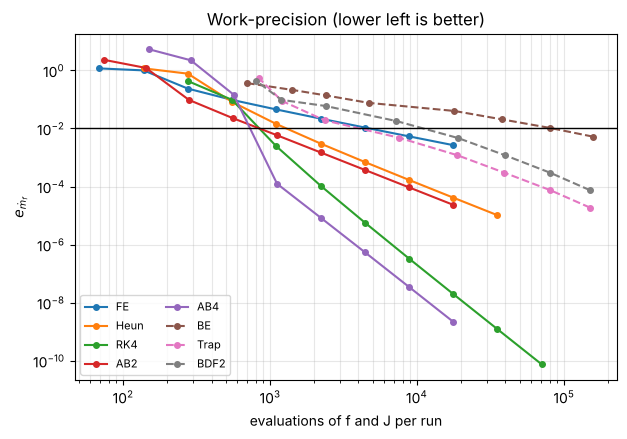

In [12]:
rows = {}
for m, (pm, impl, _) in METHODS.items():
    r = RUN_1[m]
    steps = N_REF//int(round(r["dt"]/DT_REF))
    rows[m] = {"p": pm, "w*": W_STAR[m] if W_STAR[m] else np.inf,
               "dt_stab [s]": W_STAR[m]/LAM_MAX if W_STAR[m] else np.inf, "dt_1% [s]": r["dt"],
               "steps": steps, "f-evals": r["f"], "J-evals": r["J"],
               "f/step": r["f"]/steps, "J/step": r["J"]/steps, "wall time [s]": r["time"]}
table4 = pd.DataFrame(rows).T
display(table4.style.format({"p": "{:.0f}", "w*": "{:.3f}", "dt_stab [s]": "{:.3f}", "dt_1% [s]": "{:.4f}",
                             "steps": "{:.0f}", "f-evals": "{:.0f}", "J-evals": "{:.0f}",
                             "f/step": "{:.1f}", "J/step": "{:.1f}", "wall time [s]": "{:.3f}"}))

# work-precision: error vs. cost (f-evals + J-evals) for every run in the sweep
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in METHODS:
    d = dts_of(m)
    cost = [RUNS[m, x]["f"] + RUNS[m, x]["J"] for x in d]
    ax.loglog(cost, err_of(m), STY(m), marker="o", ms=4, color=COL[m], label=m)
ax.axhline(TOL, color="k", lw=1)
ax.set(xlabel="evaluations of f and J per run", ylabel=r"$e_{\dot m_f}$", title="Work-precision (lower left is better)")
ax.legend(fontsize=8, ncol=2); ax.grid(True, which="both", alpha=0.3)
fig.savefig(f"{FIG_DIR}/fig_work_precision.pdf", bbox_inches="tight"); plt.show()

## 5. Algorithm: RK4 to burnout  (report Sec. 2.7)

Fixed-step RK4 until the step that would take $m_f$ below zero. That last step is shortened to $h \le \Delta t$, with $h$ found by Newton's method on $g(h) = m_f$ after an RK4 step of length $h$. Since $dm_f/dt = -\dot m_f$, $g'(h) \approx -\dot m_f$.

In [13]:
def rk4_burn(dt, u_init=u0, tol_mf=1e-10):
    "RK4 from u_init until m_f = 0. Returns times, states and the burnout time t_f."
    rhs = lambda u: f(u, p)
    T, U = [0.0], [u_init.copy()]
    while True:
        un = rk4_step(rhs, U[-1], dt)
        if un[4] > 0:                                   # full step, fuel left
            T.append(T[-1] + dt); U.append(un); continue
        # last step: Newton on h so that m_f(u_k -> h) = 0, starting from the linear estimate
        uk = U[-1]
        h = uk[4]/mdot_f(uk, p)
        for _ in range(20):
            uh = rk4_step(rhs, uk, h)
            if abs(uh[4]) < tol_mf*u_init[4]:
                break
            h += uh[4]/mdot_f(uh, p)                    # g(h)/(-g'(h)),  g' = dm_f/dt = -mdot_f
        T.append(T[-1] + h); U.append(uh)
        return np.array(T), np.array(U), T[-1]

T_ref_b, U_ref_b, TF_REF = rk4_burn(DT_REF)
print(f"burnout (dt_ref): t_f = {TF_REF:.6f} s, m_f(t_f) = {U_ref_b[-1, 4]:.1e} kg")
rows = []
for dt in [0.4, 0.2, 0.1, 0.05, 0.025]:
    _, Ub, tf = rk4_burn(dt)
    rows.append([dt, tf, abs(tf - TF_REF), Ub[-1, 4]])
display(pd.DataFrame(rows, columns=["dt [s]", "t_f [s]", "|t_f - t_f,ref| [s]", "m_f(t_f) [kg]"])
        .style.format({"dt [s]": "{:.3f}", "t_f [s]": "{:.6f}", "|t_f - t_f,ref| [s]": "{:.1e}", "m_f(t_f) [kg]": "{:.1e}"}))

# P_p range along the burn: stays above the 3000 psig K-breakpoint, so f is smooth for t > 0 (Sec. 2.3)
P_P = np.array([info(u, p)["P_p"] for u in U_ref_b])
print(f"P_p: {P_P.min()/PSI - 14.7:.0f} - {P_P.max()/PSI - 14.7:.0f} psig")

burnout (dt_ref): t_f = 27.917985 s, m_f(t_f) = 1.1e-13 kg


,dt [s],t_f [s],"|t_f - t_f,ref| [s]",m_f(t_f) [kg]
0,0.400,27.880982,3.7e-02,1.6e-11
1,0.200,27.926280,8.3e-03,1.9e-13
2,0.100,27.918117,1.3e-04,3.5e-18
3,0.050,27.917991,5.8e-06,1.7e-17
4,0.025,27.917986,3.1e-07,4.7e-17


P_p: 3141 - 3900 psig
